# Eksplorasi Insight Mahasiswa CDW 2026

Notebook ini menggabungkan lima dataset resmi untuk mencari hubungan yang menarik antara kondisi sosial-ekonomi mahasiswa dan capaian mereka, termasuk:

- kategori ekonomi, UKT, pendapatan orang tua, tanggungan, dan tempat tinggal;
- status generasi pertama kuliah, dukungan keluarga, kendala utama, dan program pendampingan;
- beasiswa, sumber pembiayaan, serta bekerja sambil kuliah;
- IPK terkini, lintasan IP/semester, status mahasiswa, dan riwayat prestasi;
- kombinasi kondisi yang sering tersembunyi ketika variabel dilihat satu per satu.

**Prinsip interpretasi:** seluruh hasil merupakan hubungan deskriptif/asosiasi, bukan bukti sebab-akibat. Dataset dinyatakan panitia sebagai data fiktif yang dirancang menyerupai kondisi nyata. Untuk lintasan IPK, perbandingan utama memakai mahasiswa yang sama pada semester 1 dan 4 agar tidak tercampur perubahan komposisi mahasiswa.

## 0. Menyiapkan pustaka

Sel berikut memeriksa pustaka yang diperlukan dan memasangnya bila belum tersedia. Jika lingkungan sudah lengkap, tidak ada instalasi ulang.

In [1]:
import importlib.util, subprocess, sys

required = {
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "scipy": "scipy",
    "statsmodels": "statsmodels",
    "sklearn": "scikit-learn",
    "jinja2": "jinja2",
}
missing = [pkg for module, pkg in required.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Memasang pustaka:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("Semua pustaka analisis tersedia.")

Semua pustaka analisis tersedia.


In [2]:
%matplotlib inline
from pathlib import Path
from itertools import combinations
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")

COLORS = {
    "blue": "#173F5F", "cyan": "#00A6A6", "orange": "#F4A261",
    "red": "#E76F51", "green": "#2A9D8F", "gray": "#6B7280"
}
plt.rcParams.update({"figure.figsize": (10, 5.5), "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})
print("Versi pandas:", pd.__version__)

Versi pandas: 2.3.3


## 1. Memuat dan mengaudit data

Notebook mencari folder yang berisi file sumber, sehingga tetap berjalan ketika dibuka dari folder proyek atau subfolder notebook.

In [3]:
FILENAMES = {
    "profil": "1_profil_mahasiswa_umum.csv",
    "prestasi": "2_prestasi_mahasiswa.csv",
    "generasi": "3_generasi_pertama_kuliah.csv",
    "ekonomi": "4_status_sosial_ekonomi.csv",
    "ipk": "5_riwayat_ipk_semester.csv",
}

candidates = [p / "02_Analisis" / "data" for p in [Path.cwd(), *Path.cwd().parents]] + [p / "data" for p in [Path.cwd(), *Path.cwd().parents]] + [Path.cwd(), *Path.cwd().parents]
DATA_DIR = next((p for p in candidates if (p / FILENAMES["profil"]).exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Folder dataset tidak ditemukan. Jalankan notebook dari folder yang berisi lima CSV.")

raw = {name: pd.read_csv(DATA_DIR / filename, sep=";") for name, filename in FILENAMES.items()}
print("Folder data:", DATA_DIR.resolve())
pd.DataFrame({k: {"baris": len(v), "kolom": v.shape[1], "ID unik": v.ID_Mahasiswa.nunique()} for k, v in raw.items()}).T

Folder data: C:\Users\ACER\OneDrive\Dokumen\COMPETITION\CAMPUS DATA WEEK


,baris,kolom,ID unik
profil,5000,12,5000
prestasi,6414,8,2885
generasi,5000,10,5000
ekonomi,5000,10,5000
ipk,25099,4,5000


In [4]:
audit_rows = []
for name, df in raw.items():
    audit_rows.append({
        "tabel": name,
        "baris": len(df),
        "kolom": df.shape[1],
        "ID_unik": df.ID_Mahasiswa.nunique(),
        "sel_kosong": int(df.isna().sum().sum()),
        "baris_duplikat_identik": int(df.duplicated().sum()),
        "ID_duplikat": int(df.ID_Mahasiswa.duplicated().sum()),
    })
audit = pd.DataFrame(audit_rows)
display(audit)

print("Kolom per tabel:")
for name, df in raw.items():
    print(f"\n{name}: {list(df.columns)}")

,tabel,baris,kolom,ID_unik,sel_kosong,baris_duplikat_identik,ID_duplikat
0,profil,5000,12,5000,0,0,0
1,prestasi,6414,8,2885,0,7,3529
2,generasi,5000,10,5000,0,0,0
3,ekonomi,5000,10,5000,0,0,0
4,ipk,25099,4,5000,0,0,20099


Kolom per tabel:

profil: ['ID_Mahasiswa', 'Jenis_Kelamin', 'Usia', 'Provinsi_Asal', 'Fakultas', 'Program_Studi', 'Angkatan', 'Sumber_Pembiayaan', 'Status_Mahasiswa', 'IPK_Mahasiswa', 'Masa_Studi_Semester', 'Tempat_Tinggal']

prestasi: ['ID_Mahasiswa', 'Jenis_Prestasi', 'Bidang_Kegiatan', 'Tingkat_Kegiatan', 'Capaian_Prestasi', 'Tahun_Perolehan', 'Penyelenggara', 'Jumlah_Prestasi_Kumulatif']

generasi: ['ID_Mahasiswa', 'Status_Generasi_Pertama', 'Pendidikan_Terakhir_Ayah', 'Pendidikan_Terakhir_Ibu', 'Pekerjaan_Ayah', 'Pekerjaan_Ibu', 'Jumlah_Saudara_Kuliah', 'Tingkat_Dukungan_Keluarga', 'Kendala_Utama', 'Ikut_Program_Pendampingan']

ekonomi: ['ID_Mahasiswa', 'Kategori_Ekonomi', 'Pendapatan_Orang_Tua_per_Bulan', 'Jumlah_Tanggungan_Keluarga', 'Sumber_Pembiayaan', 'Status_Penerima_Beasiswa', 'Jenis_Beasiswa', 'Kategori_UKT', 'Kepemilikan_Rumah', 'Bekerja_Sambil_Kuliah']

ipk: ['ID_Mahasiswa', 'Semester_Ke', 'IP_Semester', 'IPK_Kumulatif']


In [5]:
profil = raw["profil"].copy()
prestasi_raw = raw["prestasi"].copy()
generasi = raw["generasi"].copy()
ekonomi = raw["ekonomi"].copy()
riwayat = raw["ipk"].copy()

integrity = {
    "ID profil unik": profil.ID_Mahasiswa.is_unique,
    "ID generasi unik": generasi.ID_Mahasiswa.is_unique,
    "ID ekonomi unik": ekonomi.ID_Mahasiswa.is_unique,
    "Semua ID generasi ada di profil": set(generasi.ID_Mahasiswa) == set(profil.ID_Mahasiswa),
    "Semua ID ekonomi ada di profil": set(ekonomi.ID_Mahasiswa) == set(profil.ID_Mahasiswa),
    "Semua ID IPK ada di profil": set(riwayat.ID_Mahasiswa) == set(profil.ID_Mahasiswa),
    "Sumber pembiayaan konsisten": profil.set_index("ID_Mahasiswa").Sumber_Pembiayaan.equals(ekonomi.set_index("ID_Mahasiswa").Sumber_Pembiayaan),
}
display(pd.Series(integrity, name="hasil_audit").to_frame())

duplicate_achievements = prestasi_raw[prestasi_raw.duplicated(keep=False)].sort_values("ID_Mahasiswa")
print(f"Baris prestasi identik: {prestasi_raw.duplicated().sum()}. Analisis kejadian memakai baris unik.")
display(duplicate_achievements.head(10))
prestasi = prestasi_raw.drop_duplicates().copy()

,hasil_audit
ID profil unik,True
ID generasi unik,True
ID ekonomi unik,True
Semua ID generasi ada di profil,True
Semua ID ekonomi ada di profil,True
Semua ID IPK ada di profil,True
Sumber pembiayaan konsisten,True


Baris prestasi identik: 7. Analisis kejadian memakai baris unik.


,ID_Mahasiswa,Jenis_Prestasi,Bidang_Kegiatan,Tingkat_Kegiatan,Capaian_Prestasi,Tahun_Perolehan,Penyelenggara,Jumlah_Prestasi_Kumulatif
850,MHS00644,Non-Akademik,Sosial & Kemasyarakatan,Tingkat Nasional,Peserta,2024,Kemendikbudristek,2
851,MHS00644,Non-Akademik,Sosial & Kemasyarakatan,Tingkat Nasional,Peserta,2024,Kemendikbudristek,2
3258,MHS02520,Akademik,Debat & Karya Tulis,Tingkat Kampus,Finalis,2024,Komunitas/Organisasi,3
3259,MHS02520,Akademik,Debat & Karya Tulis,Tingkat Kampus,Finalis,2024,Komunitas/Organisasi,3
3718,MHS02891,Akademik,Debat & Karya Tulis,Tingkat Kampus,Juara 2,2024,Pemerintah Daerah,8
3720,MHS02891,Akademik,Debat & Karya Tulis,Tingkat Kampus,Juara 2,2024,Pemerintah Daerah,8
4320,MHS03336,Non-Akademik,Seni & Budaya,Tingkat Kampus,Juara 3,2025,Pemerintah Daerah,6
4321,MHS03336,Non-Akademik,Seni & Budaya,Tingkat Kampus,Juara 3,2025,Pemerintah Daerah,6
4449,MHS03455,Akademik,Sains & Teknologi,Tingkat Lokal/Wilayah,Juara 2,2025,Kemendikbudristek,3
4450,MHS03455,Akademik,Sains & Teknologi,Tingkat Lokal/Wilayah,Juara 2,2025,Kemendikbudristek,3


### Keputusan pembersihan

- Baris prestasi yang identik dihapus agar jumlah kejadian tidak berlipat.
- Mahasiswa yang tidak muncul di tabel prestasi diberi label **tidak memiliki catatan prestasi**, bukan “tidak berprestasi”.
- Nilai IPK profil diperiksa terhadap catatan kumulatif terakhir.

In [6]:
last_history = (riwayat.sort_values(["ID_Mahasiswa", "Semester_Ke"])
                .groupby("ID_Mahasiswa").tail(1)
                .set_index("ID_Mahasiswa")["IPK_Kumulatif"])
ipk_check = profil.set_index("ID_Mahasiswa")["IPK_Mahasiswa"].sub(last_history).abs()
display(ipk_check.describe().rename("selisih_absolut_IPK").to_frame())
assert np.isclose(ipk_check.max(), 0), "IPK profil tidak konsisten dengan riwayat terakhir."

,selisih_absolut_IPK
count,"5,000.000"
mean,0.000
std,0.000
min,0.000
25%,0.000
50%,0.000
75%,0.000
max,0.000


## 2. Membentuk tabel analisis per mahasiswa

Setiap mahasiswa menjadi satu baris. Riwayat prestasi dan IPK diringkas tanpa kehilangan tabel kejadian aslinya.

In [7]:
level_order = {
    "Tingkat Kampus": 1,
    "Tingkat Lokal/Wilayah": 2,
    "Tingkat Nasional": 3,
    "Tingkat Internasional": 4,
}
achievement_order = {"Peserta": 1, "Finalis": 2, "Juara 3": 3, "Juara 2": 4, "Juara 1": 5}
prestasi["skor_tingkat"] = prestasi["Tingkat_Kegiatan"].map(level_order)
prestasi["skor_capaian"] = prestasi["Capaian_Prestasi"].map(achievement_order).fillna(0)

prestasi_mhs = prestasi.groupby("ID_Mahasiswa").agg(
    jumlah_prestasi=("ID_Mahasiswa", "size"),
    jumlah_akademik=("Jenis_Prestasi", lambda s: int((s == "Akademik").sum())),
    jumlah_nonakademik=("Jenis_Prestasi", lambda s: int((s == "Non-Akademik").sum())),
    tingkat_tertinggi=("skor_tingkat", "max"),
    capaian_tertinggi=("skor_capaian", "max"),
    ragam_bidang=("Bidang_Kegiatan", "nunique"),
    tahun_prestasi_awal=("Tahun_Perolehan", "min"),
    tahun_prestasi_akhir=("Tahun_Perolehan", "max"),
).reset_index()

wide_ipk = riwayat.pivot(index="ID_Mahasiswa", columns="Semester_Ke", values="IPK_Kumulatif")
wide_ips = riwayat.pivot(index="ID_Mahasiswa", columns="Semester_Ke", values="IP_Semester")

def safe_col(frame, col):
    return frame[col] if col in frame.columns else pd.Series(np.nan, index=frame.index)

ipk_mhs = riwayat.groupby("ID_Mahasiswa").agg(
    semester_tercatat=("Semester_Ke", "max"),
    rata_ips=("IP_Semester", "mean"),
    sd_ips=("IP_Semester", "std"),
    ips_min=("IP_Semester", "min"),
    ips_max=("IP_Semester", "max"),
).join(pd.DataFrame({
    "ipk_s1": safe_col(wide_ipk, 1), "ipk_s2": safe_col(wide_ipk, 2),
    "ipk_s4": safe_col(wide_ipk, 4), "ipk_s6": safe_col(wide_ipk, 6),
    "ipk_s8": safe_col(wide_ipk, 8),
})).reset_index()
ipk_mhs["kenaikan_ipk_1_4"] = ipk_mhs["ipk_s4"] - ipk_mhs["ipk_s1"]
ipk_mhs["kenaikan_ipk_1_8"] = ipk_mhs["ipk_s8"] - ipk_mhs["ipk_s1"]

df = (profil.merge(generasi, on="ID_Mahasiswa", validate="one_to_one")
      .merge(ekonomi, on="ID_Mahasiswa", validate="one_to_one", suffixes=("_profil", "_ekonomi"))
      .merge(prestasi_mhs, on="ID_Mahasiswa", how="left")
      .merge(ipk_mhs, on="ID_Mahasiswa", how="left"))

prestasi_cols = ["jumlah_prestasi", "jumlah_akademik", "jumlah_nonakademik", "tingkat_tertinggi", "capaian_tertinggi", "ragam_bidang"]
df[prestasi_cols] = df[prestasi_cols].fillna(0)
df["punya_catatan_prestasi"] = df["jumlah_prestasi"].gt(0)
df["punya_prestasi_int"] = df["punya_catatan_prestasi"].astype(int)
df["prestasi_nasional_plus"] = df["tingkat_tertinggi"].ge(3)
df["generasi_pertama"] = df["Status_Generasi_Pertama"].eq("Ya")
df["bekerja"] = df["Bekerja_Sambil_Kuliah"].eq("Ya")
df["beasiswa"] = df["Status_Penerima_Beasiswa"].eq("Ya")
df["cuti_atau_nonaktif"] = df["Status_Mahasiswa"].isin(["Cuti", "Non-Aktif/DO"])
df["dukungan_keluarga_band"] = pd.cut(df["Tingkat_Dukungan_Keluarga"], [0, 2, 3, 5], labels=["Rendah (1-2)", "Sedang (3)", "Tinggi (4-5)"])
df.shape

(5000, 58)

In [8]:
overview = pd.Series({
    "Mahasiswa": len(df),
    "Generasi pertama": f"{df.generasi_pertama.mean():.1%}",
    "Penerima beasiswa": f"{df.beasiswa.mean():.1%}",
    "Bekerja sambil kuliah": f"{df.bekerja.mean():.1%}",
    "Memiliki catatan prestasi": f"{df.punya_catatan_prestasi.mean():.1%}",
    "Prestasi nasional/internasional": f"{df.prestasi_nasional_plus.mean():.1%}",
    "Rata-rata IPK terakhir": f"{df.IPK_Mahasiswa.mean():.2f}",
    "Cuti/nonaktif": f"{df.cuti_atau_nonaktif.mean():.1%}",
}, name="Nilai")
display(overview.to_frame())

,Nilai
Mahasiswa,5000
Generasi pertama,38.5%
Penerima beasiswa,34.1%
Bekerja sambil kuliah,24.6%
Memiliki catatan prestasi,57.7%
Prestasi nasional/internasional,23.2%
Rata-rata IPK terakhir,3.20
Cuti/nonaktif,9.9%


## 3. Profil populasi dan kondisi ekonomi

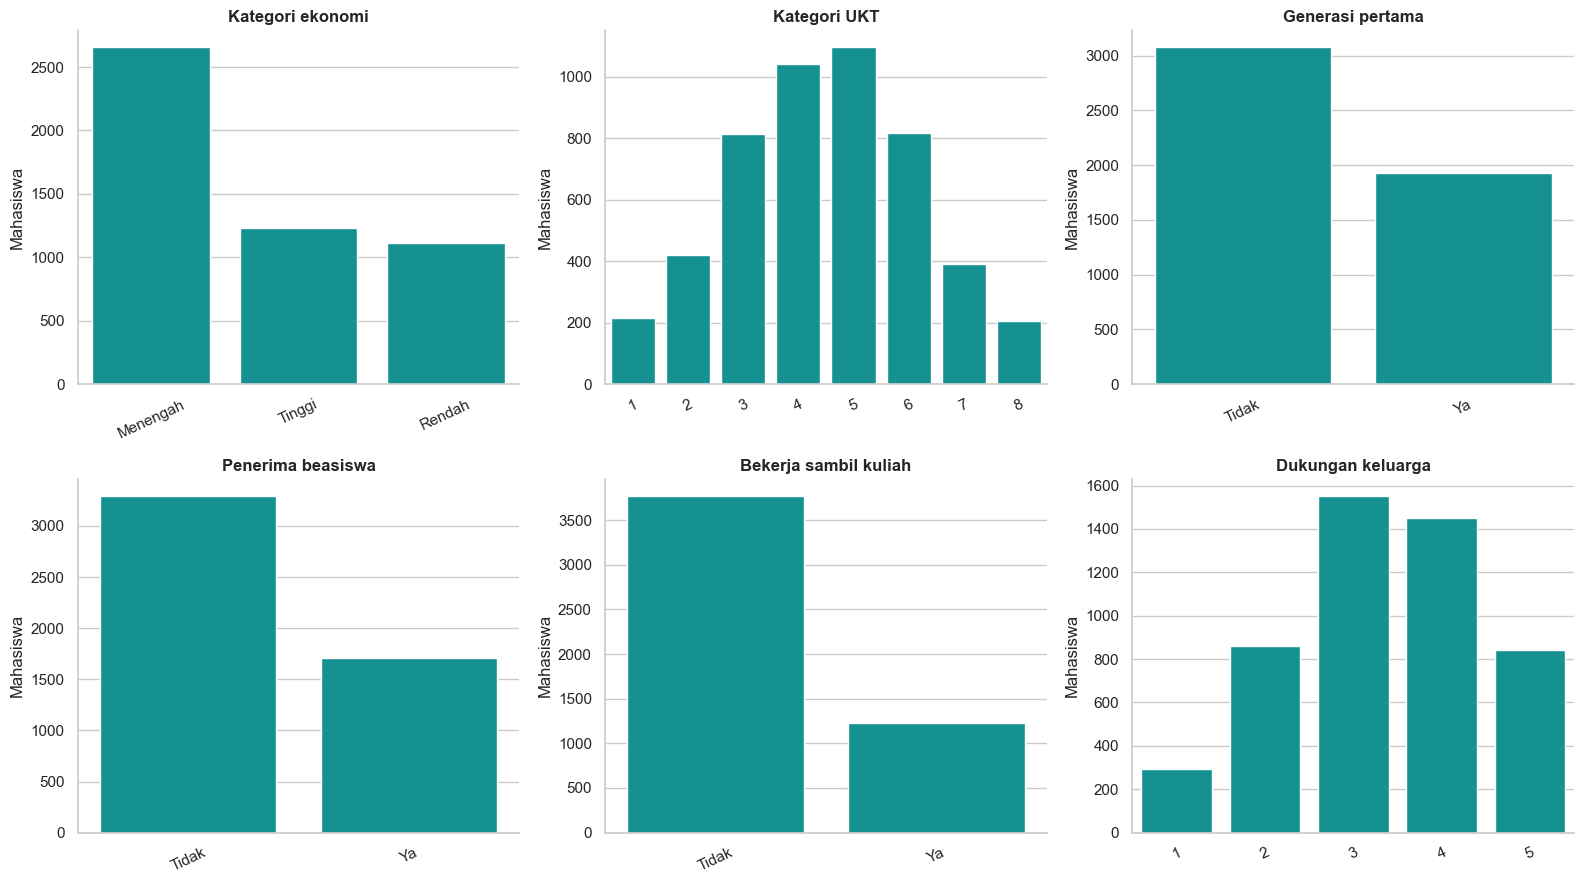

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
variables = [
    ("Kategori_Ekonomi", "Kategori ekonomi"), ("Kategori_UKT", "Kategori UKT"),
    ("Status_Generasi_Pertama", "Generasi pertama"), ("Status_Penerima_Beasiswa", "Penerima beasiswa"),
    ("Bekerja_Sambil_Kuliah", "Bekerja sambil kuliah"), ("Tingkat_Dukungan_Keluarga", "Dukungan keluarga"),
]
for ax, (col, title) in zip(axes.flat, variables):
    order = sorted(df[col].dropna().unique()) if col in ["Kategori_UKT", "Tingkat_Dukungan_Keluarga"] else df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, ax=ax, color=COLORS["cyan"])
    ax.set_title(title); ax.set_xlabel(""); ax.set_ylabel("Mahasiswa")
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

Bekerja_Sambil_Kuliah                    Tidak          Ya        All
Status_Penerima_Beasiswa                 Tidak    Ya Tidak   Ya      
Kategori_Ekonomi Status_Generasi_Pertama                             
Menengah         Tidak                     953   392   236   81  1662
                 Ya                        444   243   223   84   994
Rendah           Tidak                      95   109    49   50   303
                 Ya                        127   304   153  224   808
Tinggi           Tidak                     812   187   104    8  1111
                 Ya                         85    21    14    2   122
All                                       2516  1256   779  449  5000

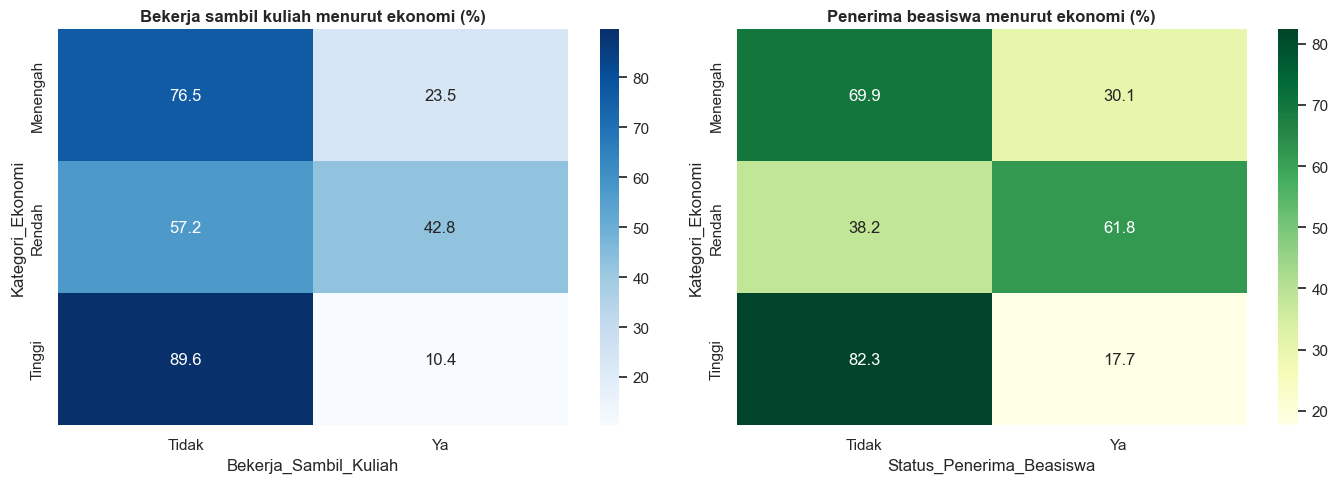

In [10]:
economic_profile = pd.crosstab(
    [df["Kategori_Ekonomi"], df["Status_Generasi_Pertama"]],
    [df["Bekerja_Sambil_Kuliah"], df["Status_Penerima_Beasiswa"]],
    margins=True,
)
display(economic_profile)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(pd.crosstab(df.Kategori_Ekonomi, df.Bekerja_Sambil_Kuliah, normalize="index") * 100,
            annot=True, fmt=".1f", cmap="Blues", ax=axes[0])
axes[0].set_title("Bekerja sambil kuliah menurut ekonomi (%)")
sns.heatmap(pd.crosstab(df.Kategori_Ekonomi, df.Status_Penerima_Beasiswa, normalize="index") * 100,
            annot=True, fmt=".1f", cmap="YlGn", ax=axes[1])
axes[1].set_title("Penerima beasiswa menurut ekonomi (%)")
plt.tight_layout(); plt.show()

## 4. IPK saat ini dan lintasan akademik

Grafik distribusi menunjukkan variasi, bukan hanya rata-rata. Selanjutnya, lintasan semester diperiksa bersama jumlah mahasiswa pada tiap semester karena semester lanjut memiliki sampel lebih kecil.

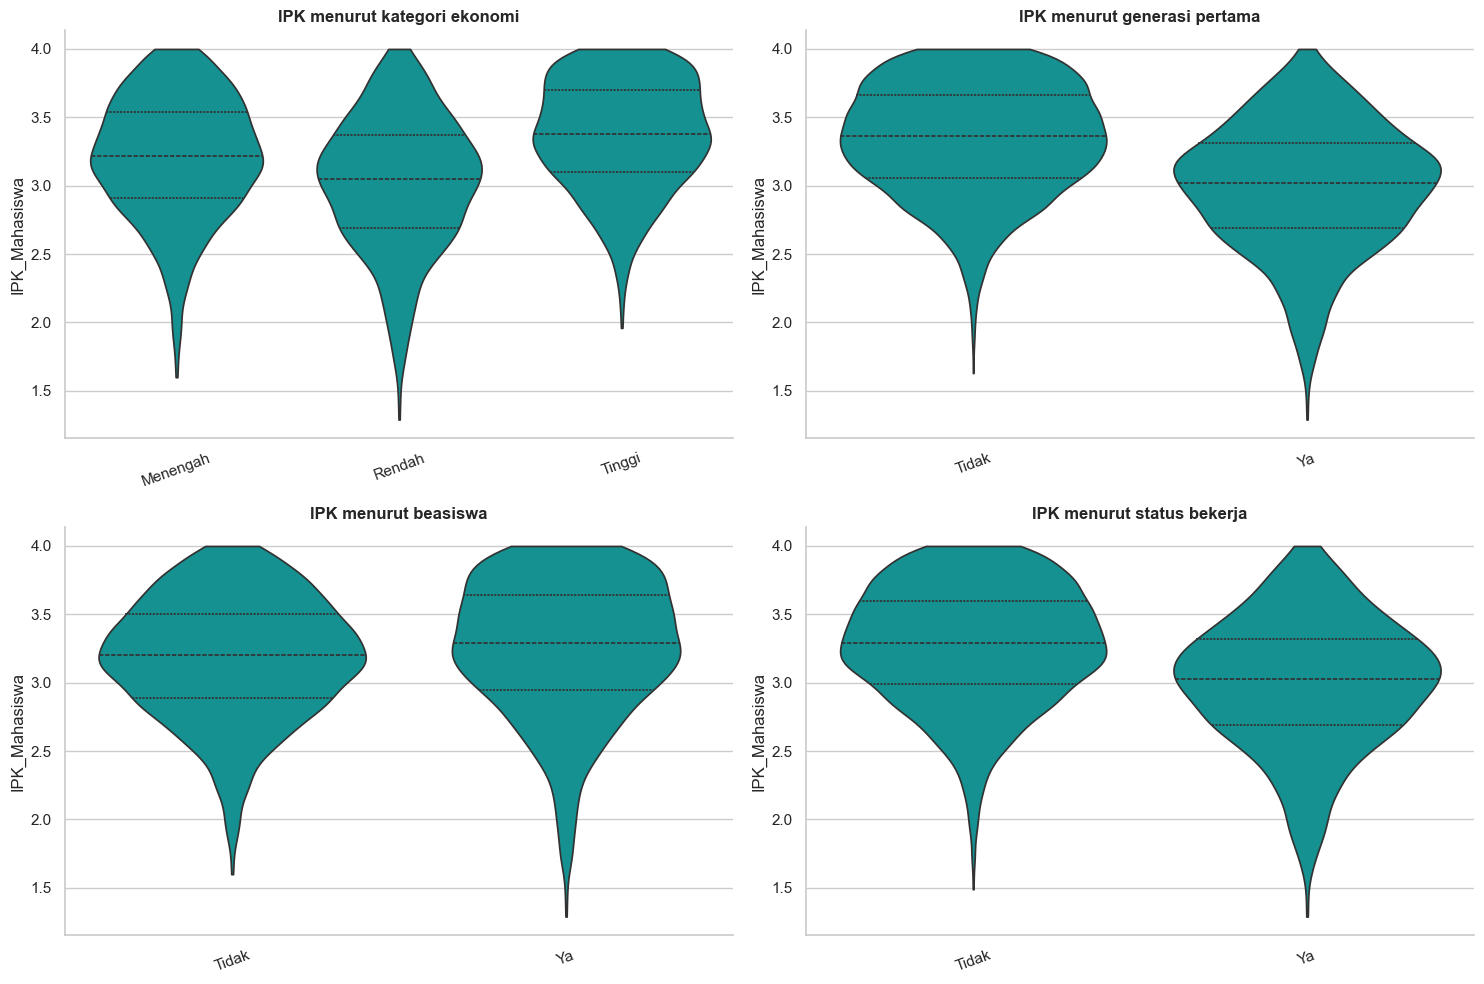

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, col, title in [
    (axes[0,0], "Kategori_Ekonomi", "IPK menurut kategori ekonomi"),
    (axes[0,1], "Status_Generasi_Pertama", "IPK menurut generasi pertama"),
    (axes[1,0], "Status_Penerima_Beasiswa", "IPK menurut beasiswa"),
    (axes[1,1], "Bekerja_Sambil_Kuliah", "IPK menurut status bekerja"),
]:
    sns.violinplot(data=df, x=col, y="IPK_Mahasiswa", inner="quartile", cut=0, ax=ax, color=COLORS["cyan"])
    ax.set_title(title); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

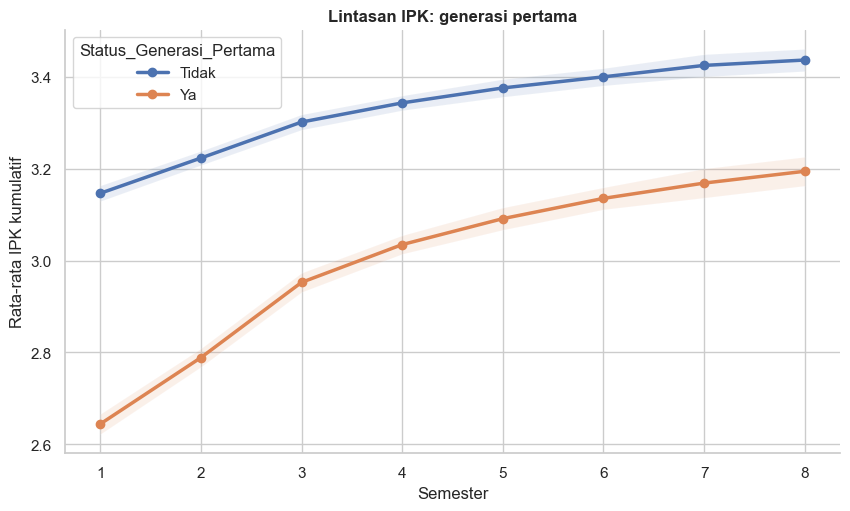

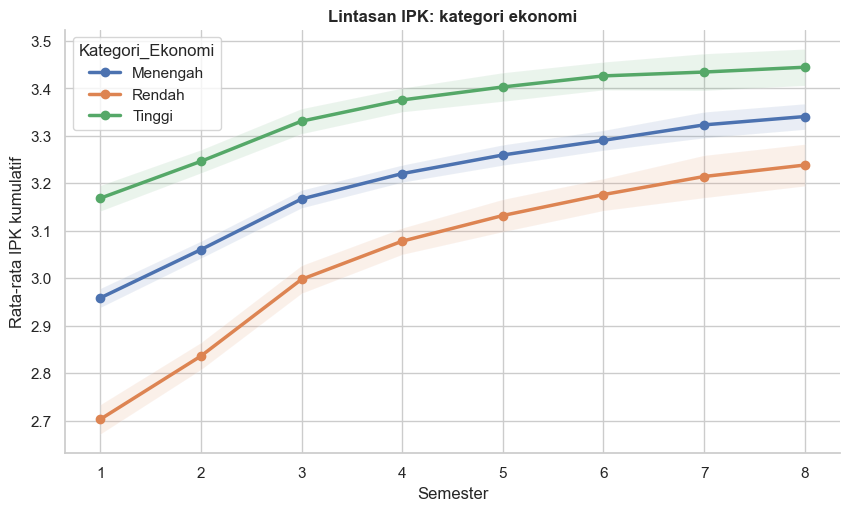

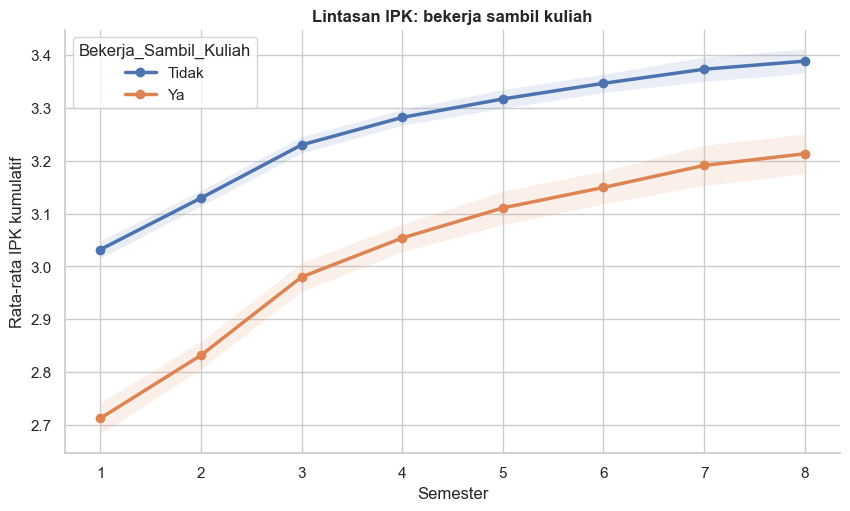

In [12]:
def trajectory_plot(group_col, title, max_semester=8):
    tmp = riwayat.merge(df[["ID_Mahasiswa", group_col]], on="ID_Mahasiswa")
    tmp = tmp[tmp.Semester_Ke <= max_semester]
    summary = tmp.groupby([group_col, "Semester_Ke"]).agg(
        n=("ID_Mahasiswa", "nunique"), mean_ipk=("IPK_Kumulatif", "mean"), se=("IPK_Kumulatif", "sem")
    ).reset_index()
    plt.figure(figsize=(10, 5.5))
    for label, part in summary.groupby(group_col):
        plt.plot(part.Semester_Ke, part.mean_ipk, marker="o", linewidth=2.5, label=f"{label}")
        plt.fill_between(part.Semester_Ke, part.mean_ipk-1.96*part.se, part.mean_ipk+1.96*part.se, alpha=.12)
    plt.title(title); plt.xlabel("Semester"); plt.ylabel("Rata-rata IPK kumulatif"); plt.legend(title=group_col)
    plt.show()
    return summary

traj_gen = trajectory_plot("Status_Generasi_Pertama", "Lintasan IPK: generasi pertama")
traj_eko = trajectory_plot("Kategori_Ekonomi", "Lintasan IPK: kategori ekonomi")
traj_work = trajectory_plot("Bekerja_Sambil_Kuliah", "Lintasan IPK: bekerja sambil kuliah")

,mahasiswa,ipk_semester_1,ipk_semester_4,kenaikan
Status_Generasi_Pertama,,,,
Tidak,2258,3.157,3.343,0.186
Ya,1345,2.685,3.035,0.350


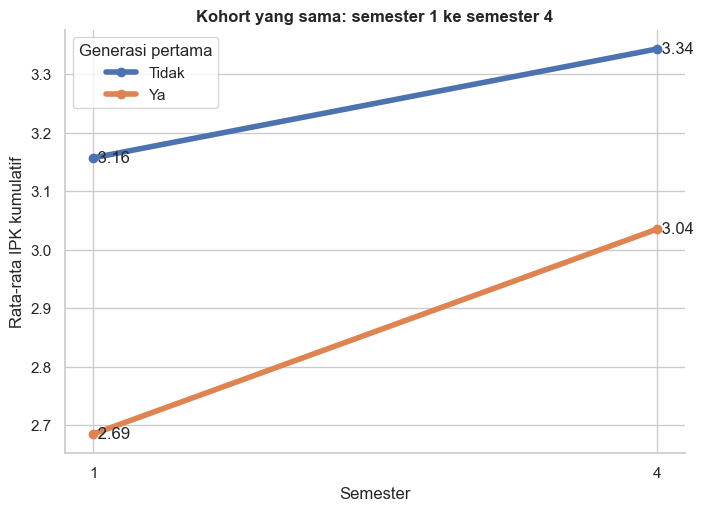

In [13]:
fixed_cohort = df.dropna(subset=["ipk_s1", "ipk_s4"]).copy()
cohort_summary = fixed_cohort.groupby("Status_Generasi_Pertama").agg(
    mahasiswa=("ID_Mahasiswa", "size"),
    ipk_semester_1=("ipk_s1", "mean"),
    ipk_semester_4=("ipk_s4", "mean"),
    kenaikan=("kenaikan_ipk_1_4", "mean"),
).round(3)
display(cohort_summary)

fig, ax = plt.subplots(figsize=(8, 5.5))
for label, row in cohort_summary.iterrows():
    ax.plot([1,4], [row.ipk_semester_1, row.ipk_semester_4], marker="o", linewidth=4, label=label)
    ax.text(1, row.ipk_semester_1, f" {row.ipk_semester_1:.2f}", va="center")
    ax.text(4, row.ipk_semester_4, f" {row.ipk_semester_4:.2f}", va="center")
ax.set_xticks([1,4]); ax.set_xlabel("Semester"); ax.set_ylabel("Rata-rata IPK kumulatif")
ax.set_title("Kohort yang sama: semester 1 ke semester 4")
ax.legend(title="Generasi pertama"); plt.show()

## 5. Prestasi: partisipasi, tingkat, bidang, dan capaian

Jumlah prestasi dihitung pada tingkat mahasiswa. Ini mencegah mahasiswa dengan banyak entri mendominasi perbandingan kelompok.

In [14]:
def outcome_summary(group_col):
    return (df.groupby(group_col, observed=True)
            .agg(n=("ID_Mahasiswa", "size"), IPK=("IPK_Mahasiswa", "mean"),
                 punya_prestasi=("punya_catatan_prestasi", "mean"),
                 nasional_plus=("prestasi_nasional_plus", "mean"),
                 rata_jumlah_prestasi=("jumlah_prestasi", "mean"),
                 bekerja=("bekerja", "mean"), beasiswa=("beasiswa", "mean"),
                 cuti_nonaktif=("cuti_atau_nonaktif", "mean"))
            .reset_index())

for col in ["Kategori_Ekonomi", "Kategori_UKT", "Status_Generasi_Pertama", "Status_Penerima_Beasiswa", "Bekerja_Sambil_Kuliah", "Tingkat_Dukungan_Keluarga"]:
    print("\n", col)
    display(outcome_summary(col).style.format({"IPK":"{:.2f}", "punya_prestasi":"{:.1%}", "nasional_plus":"{:.1%}", "rata_jumlah_prestasi":"{:.2f}", "bekerja":"{:.1%}", "beasiswa":"{:.1%}", "cuti_nonaktif":"{:.1%}"}))


 Kategori_Ekonomi


,Kategori_Ekonomi,n,IPK,punya_prestasi,nasional_plus,rata_jumlah_prestasi,bekerja,beasiswa,cuti_nonaktif
0,Menengah,2656,3.20,57.3%,22.1%,1.21,23.5%,30.1%,9.1%
1,Rendah,1111,3.02,41.7%,13.4%,0.66,42.8%,61.8%,17.2%
2,Tinggi,1233,3.37,73.0%,34.3%,2.00,10.4%,17.7%,4.9%



 Kategori_UKT


,Kategori_UKT,n,IPK,punya_prestasi,nasional_plus,rata_jumlah_prestasi,bekerja,beasiswa,cuti_nonaktif
0,1,215,2.94,39.5%,12.1%,0.59,51.2%,80.0%,19.1%
1,2,420,3.02,40.7%,12.6%,0.68,44.8%,59.3%,18.3%
2,3,813,3.08,46.2%,15.7%,0.82,31.7%,44.4%,13.5%
3,4,1042,3.17,54.0%,19.5%,1.10,25.5%,33.2%,9.6%
4,5,1095,3.26,62.6%,27.4%,1.43,21.9%,26.7%,8.0%
5,6,816,3.32,67.3%,30.4%,1.65,13.8%,22.2%,5.8%
6,7,392,3.36,74.2%,32.4%,1.92,10.5%,18.4%,4.8%
7,8,207,3.39,79.7%,35.3%,2.45,5.8%,15.5%,5.3%



 Status_Generasi_Pertama


...

,Status_Penerima_Beasiswa,n,IPK,punya_prestasi,nasional_plus,rata_jumlah_prestasi,bekerja,beasiswa,cuti_nonaktif
0,Tidak,3295,3.18,58.4%,21.2%,1.20,23.6%,0.0%,8.6%
1,Ya,1705,3.25,56.4%,27.0%,1.44,26.3%,100.0%,12.3%



 Bekerja_Sambil_Kuliah


,Bekerja_Sambil_Kuliah,n,IPK,punya_prestasi,nasional_plus,rata_jumlah_prestasi,bekerja,beasiswa,cuti_nonaktif
0,Tidak,3772,3.27,62.8%,26.2%,1.46,0.0%,33.3%,7.7%
1,Ya,1228,2.99,42.1%,13.9%,0.73,100.0%,36.6%,16.6%



 Tingkat_Dukungan_Keluarga


,Tingkat_Dukungan_Keluarga,n,IPK,punya_prestasi,nasional_plus,rata_jumlah_prestasi,bekerja,beasiswa,cuti_nonaktif
0,1,294,2.93,33.0%,13.6%,0.57,39.1%,58.8%,17.7%
1,2,862,3.04,44.3%,15.0%,0.77,31.7%,42.2%,14.8%
2,3,1553,3.17,55.8%,20.7%,1.12,27.1%,33.9%,9.9%
3,4,1450,3.28,64.2%,28.1%,1.51,20.1%,30.4%,6.8%
4,5,841,3.38,72.4%,31.0%,1.94,15.2%,23.8%,7.3%


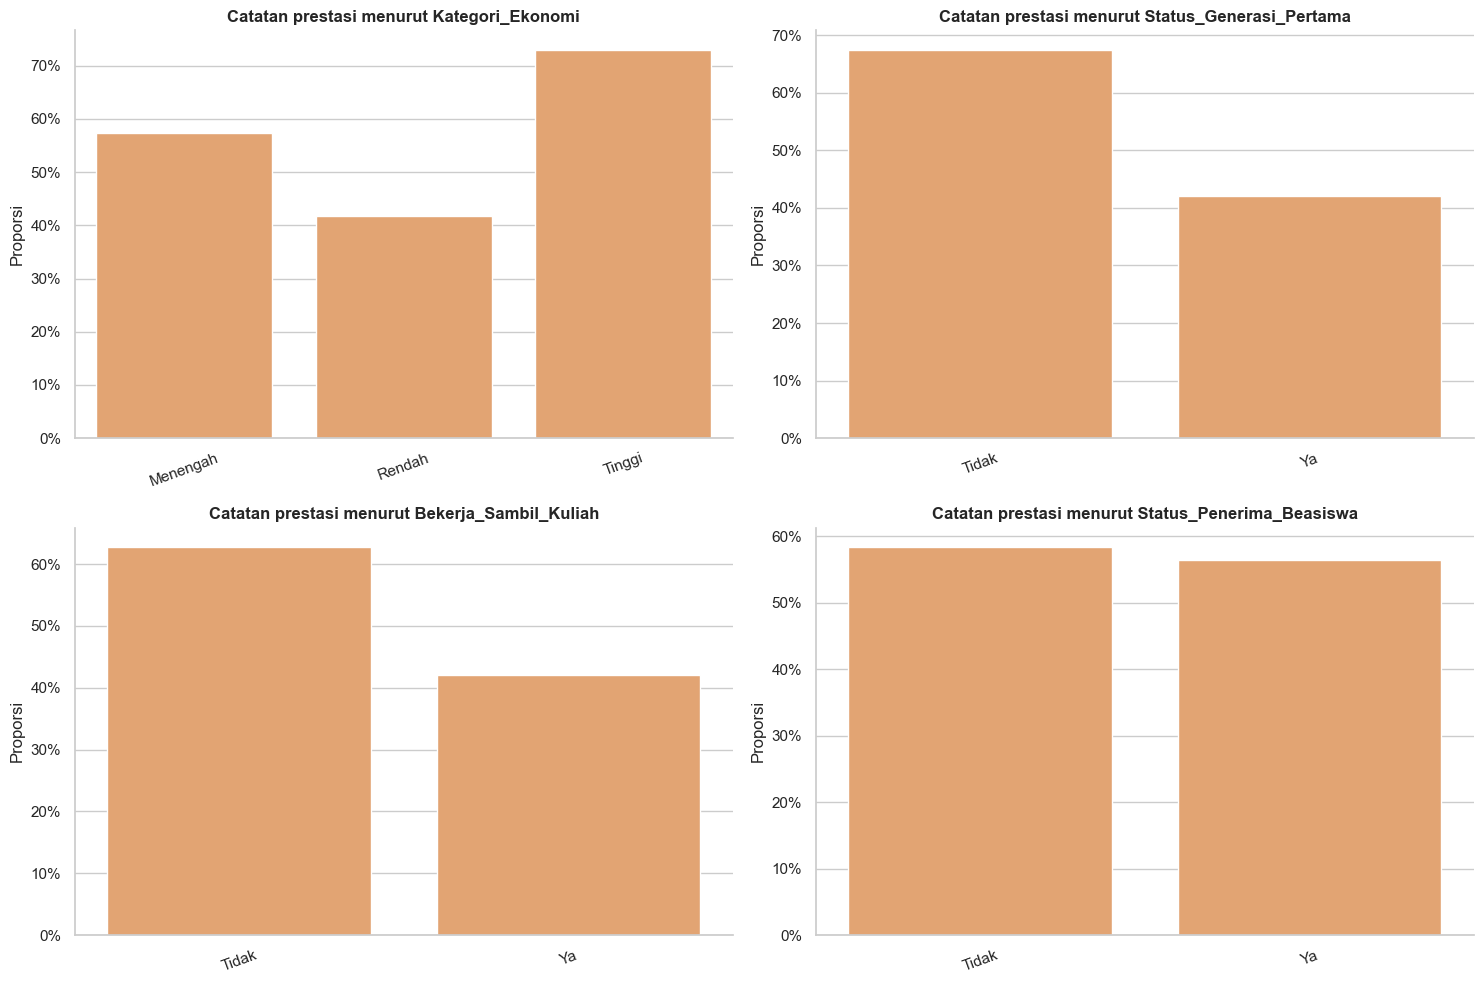

In [15]:
compare_cols = ["Kategori_Ekonomi", "Status_Generasi_Pertama", "Bekerja_Sambil_Kuliah", "Status_Penerima_Beasiswa"]
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, col in zip(axes.flat, compare_cols):
    plot_df = outcome_summary(col)
    sns.barplot(data=plot_df, x=col, y="punya_prestasi", ax=ax, color=COLORS["orange"])
    ax.set_title(f"Catatan prestasi menurut {col}"); ax.set_ylabel("Proporsi"); ax.set_xlabel("")
    ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

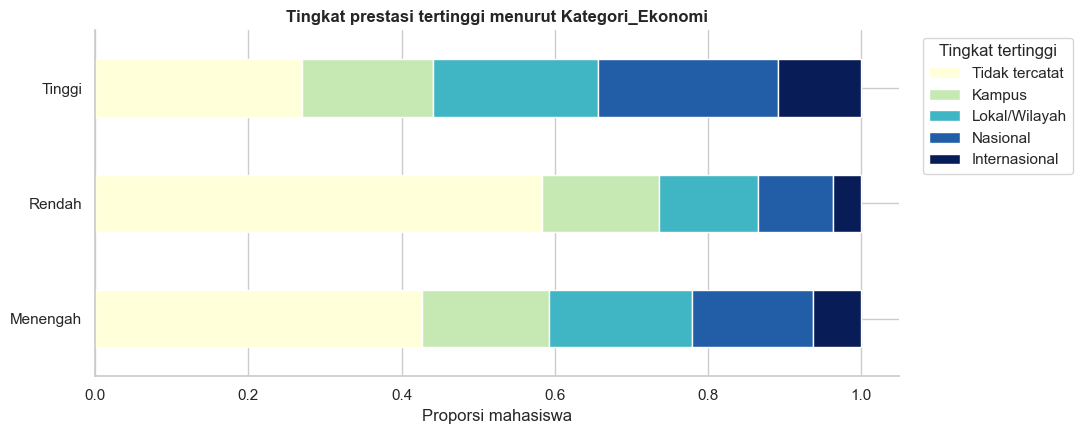

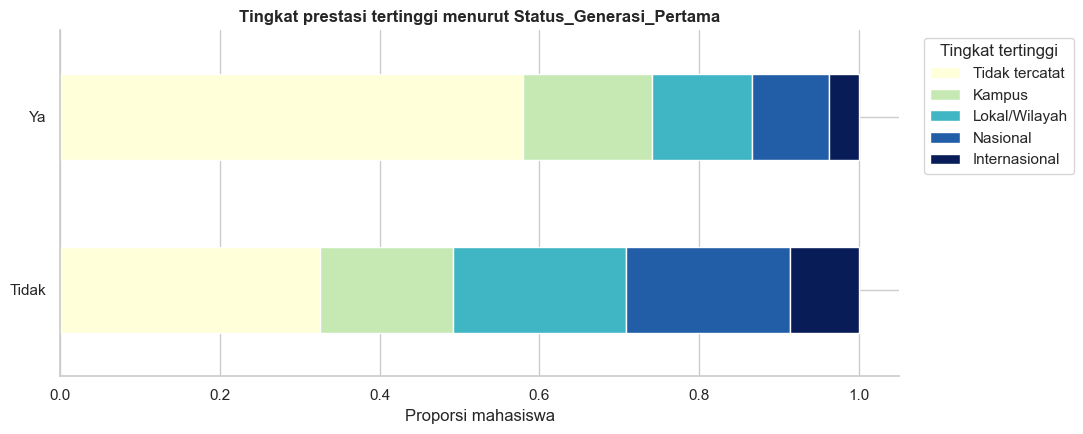

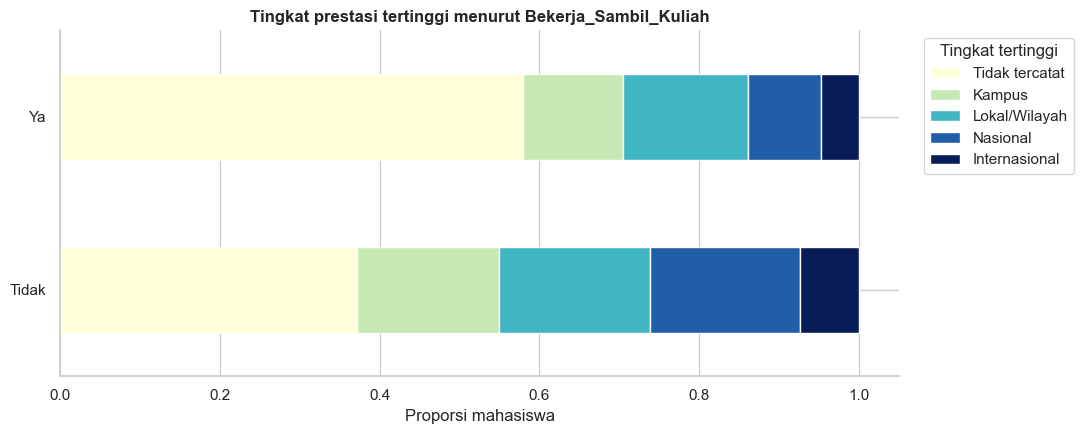

In [16]:
tier_labels = {0:"Tidak tercatat", 1:"Kampus", 2:"Lokal/Wilayah", 3:"Nasional", 4:"Internasional"}
df["level_prestasi_tertinggi"] = df.tingkat_tertinggi.map(tier_labels)
order_tier = ["Tidak tercatat", "Kampus", "Lokal/Wilayah", "Nasional", "Internasional"]

for group in ["Kategori_Ekonomi", "Status_Generasi_Pertama", "Bekerja_Sambil_Kuliah"]:
    tab = pd.crosstab(df[group], df.level_prestasi_tertinggi, normalize="index").reindex(columns=order_tier, fill_value=0)
    tab.plot(kind="barh", stacked=True, figsize=(11, 4.5), colormap="YlGnBu")
    plt.title(f"Tingkat prestasi tertinggi menurut {group}"); plt.xlabel("Proporsi mahasiswa"); plt.ylabel("")
    plt.legend(title="Tingkat tertinggi", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout(); plt.show()

,Jenis_Prestasi,Bidang_Kegiatan,jumlah
4,Akademik,Sains & Teknologi,1288
0,Akademik,Debat & Karya Tulis,1057
8,Non-Akademik,Kewirausahaan,714
11,Non-Akademik,Sosial & Kemasyarakatan,676
10,Non-Akademik,Seni & Budaya,674
9,Non-Akademik,Olahraga,664
7,Non-Akademik,Keagamaan,579
5,Akademik,Seni & Budaya,174
3,Akademik,Olahraga,164
6,Akademik,Sosial & Kemasyarakatan,151


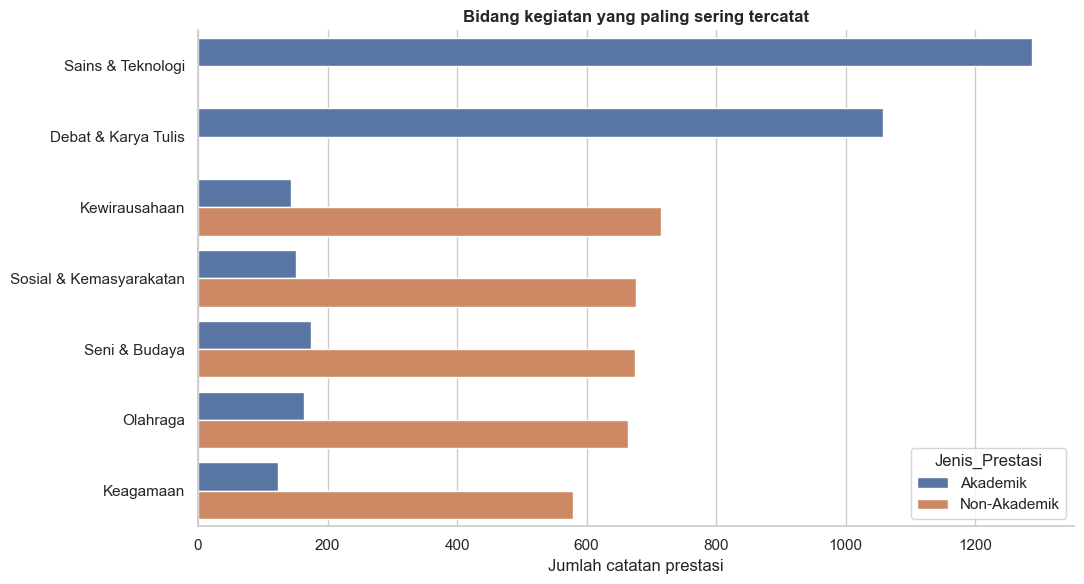

In [17]:
field = (prestasi.groupby(["Jenis_Prestasi", "Bidang_Kegiatan"]).size()
         .rename("jumlah").reset_index().sort_values("jumlah", ascending=False))
display(field.head(20))
plt.figure(figsize=(11, 6))
sns.barplot(data=field.head(15), y="Bidang_Kegiatan", x="jumlah", hue="Jenis_Prestasi")
plt.title("Bidang kegiatan yang paling sering tercatat"); plt.xlabel("Jumlah catatan prestasi"); plt.ylabel("")
plt.tight_layout(); plt.show()

## 6. Analisis interseksional

Bagian ini mencari kelompok yang membawa beberapa kondisi sekaligus. Sel dengan sampel sangat kecil harus dihindari sebagai headline.

In [18]:
intersection = (df.groupby(["Status_Generasi_Pertama", "Kategori_Ekonomi", "Bekerja_Sambil_Kuliah"], observed=True)
                .agg(n=("ID_Mahasiswa", "size"), IPK=("IPK_Mahasiswa", "mean"),
                     kenaikan_1_4=("kenaikan_ipk_1_4", "mean"),
                     prestasi=("punya_catatan_prestasi", "mean"),
                     nasional_plus=("prestasi_nasional_plus", "mean"),
                     beasiswa=("beasiswa", "mean"), cuti_nonaktif=("cuti_atau_nonaktif", "mean"))
                .reset_index().sort_values("IPK"))
display(intersection.style.format({"IPK":"{:.2f}", "kenaikan_1_4":"{:+.2f}", "prestasi":"{:.1%}", "nasional_plus":"{:.1%}", "beasiswa":"{:.1%}", "cuti_nonaktif":"{:.1%}"}))

,Status_Generasi_Pertama,Kategori_Ekonomi,Bekerja_Sambil_Kuliah,n,IPK,kenaikan_1_4,prestasi,nasional_plus,beasiswa,cuti_nonaktif
9,Ya,Rendah,Ya,377,2.81,+0.37,28.6%,6.9%,59.4%,25.5%
11,Ya,Tinggi,Ya,16,2.84,+0.27,43.8%,6.2%,12.5%,12.5%
7,Ya,Menengah,Ya,307,2.89,+0.34,34.9%,8.8%,27.4%,17.3%
8,Ya,Rendah,Tidak,431,3.03,+0.36,42.5%,14.6%,70.5%,15.3%
6,Ya,Menengah,Tidak,687,3.09,+0.34,49.3%,17.8%,35.4%,10.3%
10,Ya,Tinggi,Tidak,106,3.09,+0.34,61.3%,18.9%,19.8%,2.8%
1,Tidak,Menengah,Ya,317,3.16,+0.19,55.2%,22.4%,25.6%,9.1%
3,Tidak,Rendah,Ya,99,3.18,+0.19,48.5%,16.2%,50.5%,14.1%
5,Tidak,Tinggi,Ya,112,3.25,+0.21,64.3%,26.8%,7.1%,8.9%
2,Tidak,Rendah,Tidak,204,3.29,+0.19,60.8%,21.6%,53.4%,7.4%


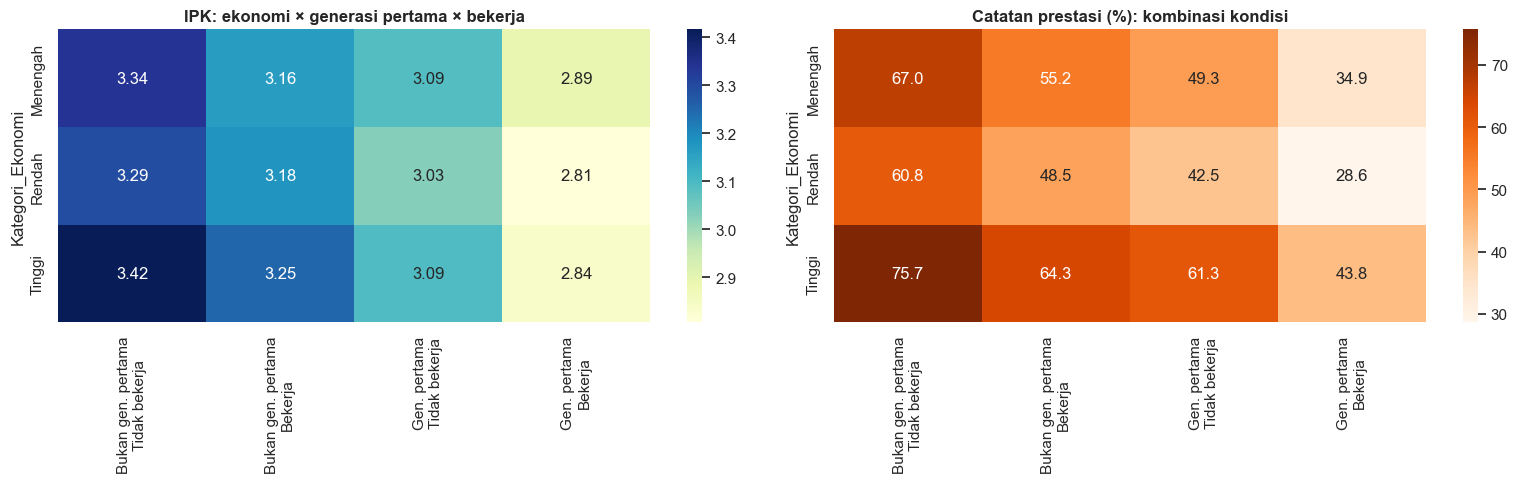

In [19]:
pivot_ipk = df.pivot_table(index="Kategori_Ekonomi", columns=["Status_Generasi_Pertama", "Bekerja_Sambil_Kuliah"], values="IPK_Mahasiswa", aggfunc="mean")
pivot_ach = df.pivot_table(index="Kategori_Ekonomi", columns=["Status_Generasi_Pertama", "Bekerja_Sambil_Kuliah"], values="punya_catatan_prestasi", aggfunc="mean")
friendly_cols = [f"{'Gen. pertama' if g == 'Ya' else 'Bukan gen. pertama'}\n{'Bekerja' if w == 'Ya' else 'Tidak bekerja'}" for g, w in pivot_ipk.columns]
pivot_ipk.columns = friendly_cols
pivot_ach.columns = friendly_cols
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.heatmap(pivot_ipk, annot=True, fmt=".2f", cmap="YlGnBu", ax=axes[0]); axes[0].set_title("IPK: ekonomi × generasi pertama × bekerja")
sns.heatmap(pivot_ach*100, annot=True, fmt=".1f", cmap="Oranges", ax=axes[1]); axes[1].set_title("Catatan prestasi (%): kombinasi kondisi")
plt.tight_layout(); plt.show()

## 7. Beasiswa, UKT, dukungan keluarga, dan pendampingan

Perbandingan beasiswa sangat rentan *selection bias*: beasiswa prestasi memang memilih mahasiswa berprestasi, sedangkan KIP-Kuliah menargetkan kebutuhan ekonomi. Karena itu jenis beasiswa harus dilihat terpisah.

In [20]:
scholarship = outcome_summary("Jenis_Beasiswa").sort_values("IPK", ascending=False)
display(scholarship.style.format({"IPK":"{:.2f}", "punya_prestasi":"{:.1%}", "nasional_plus":"{:.1%}", "rata_jumlah_prestasi":"{:.2f}", "bekerja":"{:.1%}", "beasiswa":"{:.1%}", "cuti_nonaktif":"{:.1%}"}))

within_economy = (df.groupby(["Kategori_Ekonomi", "Status_Penerima_Beasiswa"], observed=True)
                  .agg(n=("ID_Mahasiswa", "size"), IPK=("IPK_Mahasiswa", "mean"),
                       prestasi=("punya_catatan_prestasi", "mean"), nasional_plus=("prestasi_nasional_plus", "mean"),
                       bekerja=("bekerja", "mean"), cuti_nonaktif=("cuti_atau_nonaktif", "mean"))
                  .reset_index())
display(within_economy.style.format({"IPK":"{:.2f}", "prestasi":"{:.1%}", "nasional_plus":"{:.1%}", "bekerja":"{:.1%}", "cuti_nonaktif":"{:.1%}"}))

,Jenis_Beasiswa,n,IPK,punya_prestasi,nasional_plus,rata_jumlah_prestasi,bekerja,beasiswa,cuti_nonaktif
1,Beasiswa Prestasi Akademik (PPA),505,3.60,81.8%,54.1%,2.81,13.9%,100.0%,7.5%
2,Beasiswa Swasta/CSR,126,3.33,70.6%,27.0%,1.64,22.2%,100.0%,7.9%
4,Tidak Ada,3295,3.18,58.4%,21.2%,1.20,23.6%,0.0%,8.6%
0,Beasiswa Daerah,193,3.13,52.3%,13.5%,0.93,15.5%,100.0%,8.3%
3,KIP-Kuliah,881,3.06,40.6%,14.5%,0.73,36.4%,100.0%,16.6%


,Kategori_Ekonomi,Status_Penerima_Beasiswa,n,IPK,prestasi,nasional_plus,bekerja,cuti_nonaktif
0,Menengah,Tidak,1856,3.15,55.5%,18.3%,24.7%,9.1%
1,Menengah,Ya,800,3.33,61.4%,30.9%,20.6%,9.1%
2,Rendah,Tidak,424,2.97,41.3%,12.5%,47.6%,15.3%
3,Rendah,Ya,687,3.04,41.9%,14.0%,39.9%,18.3%
4,Tinggi,Tidak,1015,3.32,70.7%,30.0%,11.6%,4.9%
5,Tinggi,Ya,218,3.58,83.5%,54.1%,4.6%,5.0%


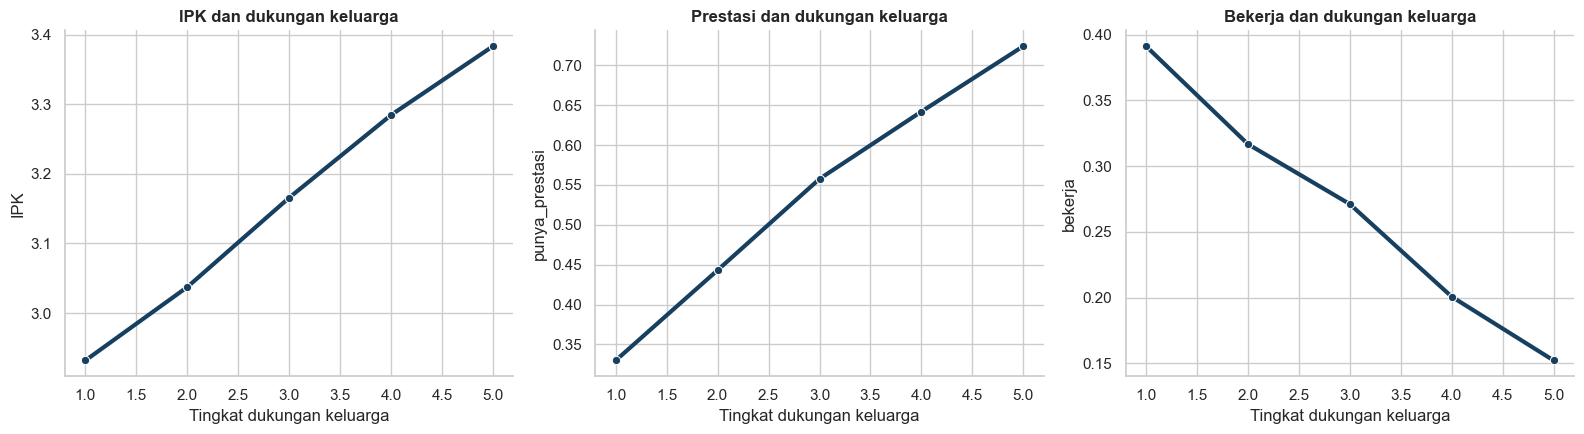

,Tingkat_Dukungan_Keluarga,n,IPK,punya_prestasi,nasional_plus,rata_jumlah_prestasi,bekerja,beasiswa,cuti_nonaktif
0,1,294,2.93,33.0%,13.6%,0.574830,39.1%,58.8%,17.7%
1,2,862,3.04,44.3%,15.0%,0.773782,31.7%,42.2%,14.8%
2,3,1553,3.17,55.8%,20.7%,1.124276,27.1%,33.9%,9.9%
3,4,1450,3.28,64.2%,28.1%,1.510345,20.1%,30.4%,6.8%
4,5,841,3.38,72.4%,31.0%,1.944114,15.2%,23.8%,7.3%


In [21]:
support = outcome_summary("Tingkat_Dukungan_Keluarga").sort_values("Tingkat_Dukungan_Keluarga")
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, y, title, fmt in [
    (axes[0], "IPK", "IPK dan dukungan keluarga", ".2f"),
    (axes[1], "punya_prestasi", "Prestasi dan dukungan keluarga", ".1%"),
    (axes[2], "bekerja", "Bekerja dan dukungan keluarga", ".1%"),
]:
    sns.lineplot(data=support, x="Tingkat_Dukungan_Keluarga", y=y, marker="o", linewidth=3, ax=ax, color=COLORS["blue"])
    ax.set_title(title); ax.set_xlabel("Tingkat dukungan keluarga")
plt.tight_layout(); plt.show()
display(support.style.format({"IPK":"{:.2f}", "punya_prestasi":"{:.1%}", "nasional_plus":"{:.1%}", "bekerja":"{:.1%}", "beasiswa":"{:.1%}", "cuti_nonaktif":"{:.1%}"}))

In [22]:
mentoring = (df.groupby(["Status_Generasi_Pertama", "Ikut_Program_Pendampingan"], observed=True)
             .agg(n=("ID_Mahasiswa", "size"), IPK=("IPK_Mahasiswa", "mean"),
                  ipk_s1=("ipk_s1", "mean"), ipk_s4=("ipk_s4", "mean"),
                  kenaikan=("kenaikan_ipk_1_4", "mean"), prestasi=("punya_catatan_prestasi", "mean"),
                  bekerja=("bekerja", "mean"), beasiswa=("beasiswa", "mean"), cuti_nonaktif=("cuti_atau_nonaktif", "mean"))
             .reset_index())
display(mentoring.style.format({"IPK":"{:.2f}", "ipk_s1":"{:.2f}", "ipk_s4":"{:.2f}", "kenaikan":"{:+.2f}", "prestasi":"{:.1%}", "bekerja":"{:.1%}", "beasiswa":"{:.1%}", "cuti_nonaktif":"{:.1%}"}))
print("Catatan: peserta pendampingan mungkin dipilih karena memiliki kebutuhan lebih tinggi. Perbedaan mentah bukan efek program.")

,Status_Generasi_Pertama,Ikut_Program_Pendampingan,n,IPK,ipk_s1,ipk_s4,kenaikan,prestasi,bekerja,beasiswa,cuti_nonaktif
0,Tidak,Tidak,2397,3.32,3.16,3.34,+0.17,68.1%,16.4%,24.5%,6.4%
1,Tidak,Ya,679,3.37,3.11,3.36,+0.25,65.4%,20.0%,35.2%,7.2%
2,Ya,Tidak,901,2.97,2.67,3.02,+0.31,44.7%,33.9%,36.3%,12.3%
3,Ya,Ya,1023,3.01,2.62,3.04,+0.38,39.7%,38.6%,53.9%,17.6%


Catatan: peserta pendampingan mungkin dipilih karena memiliki kebutuhan lebih tinggi. Perbedaan mentah bukan efek program.


## 8. Variabel lain yang mungkin memperkaya cerita

In [23]:
extra_groups = ["Sumber_Pembiayaan_ekonomi", "Tempat_Tinggal", "Kendala_Utama", "Kepemilikan_Rumah", "Jumlah_Tanggungan_Keluarga", "Jumlah_Saudara_Kuliah"]
for col in extra_groups:
    print("\n###", col)
    result = outcome_summary(col).sort_values("n", ascending=False)
    display(result.style.format({"IPK":"{:.2f}", "punya_prestasi":"{:.1%}", "nasional_plus":"{:.1%}", "rata_jumlah_prestasi":"{:.2f}", "bekerja":"{:.1%}", "beasiswa":"{:.1%}", "cuti_nonaktif":"{:.1%}"}))


### Sumber_Pembiayaan_ekonomi


,Sumber_Pembiayaan_ekonomi,n,IPK,punya_prestasi,nasional_plus,rata_jumlah_prestasi,bekerja,beasiswa,cuti_nonaktif
2,Orang Tua,3293,3.23,61.2%,24.4%,1.36,17.2%,14.2%,7.5%
0,Beasiswa,1132,3.18,50.7%,22.6%,1.23,30.3%,100.0%,14.3%
1,Kerja Sendiri (part-time),433,3.01,46.2%,16.2%,0.82,67.2%,20.1%,17.3%
3,Pinjaman/Kredit Pendidikan,142,3.14,68.3%,21.1%,1.25,18.3%,14.1%,7.0%



### Tempat_Tinggal


,Tempat_Tinggal,n,IPK,punya_prestasi,nasional_plus,rata_jumlah_prestasi,bekerja,beasiswa,cuti_nonaktif
1,Kos,2045,3.23,64.4%,27.4%,1.59,20.2%,29.2%,8.2%
3,Rumah Orang Tua,1858,3.21,53.5%,20.6%,1.08,24.4%,34.1%,9.7%
0,Asrama,803,3.13,57.0%,21.8%,1.19,33.3%,46.0%,13.7%
2,Menumpang Saudara,294,3.10,39.5%,13.3%,0.65,32.0%,35.7%,11.9%



### Kendala_Utama


...

,Kepemilikan_Rumah,n,IPK,punya_prestasi,nasional_plus,rata_jumlah_prestasi,bekerja,beasiswa,cuti_nonaktif
1,Milik Sendiri,2368,3.29,65.4%,28.5%,1.64,16.0%,24.7%,6.5%
2,Sewa,1591,3.14,54.6%,20.2%,1.05,31.2%,39.5%,12.3%
0,Menumpang,1041,3.10,45.1%,15.4%,0.82,33.8%,47.2%,13.7%



### Jumlah_Tanggungan_Keluarga


,Jumlah_Tanggungan_Keluarga,n,IPK,punya_prestasi,nasional_plus,rata_jumlah_prestasi,bekerja,beasiswa,cuti_nonaktif
3,4,1049,3.20,58.2%,23.7%,1.37,21.4%,32.3%,8.7%
2,3,1019,3.23,60.6%,25.2%,1.38,22.5%,30.3%,8.7%
4,5,825,3.19,57.2%,22.8%,1.18,27.0%,37.0%,9.1%
1,2,720,3.26,62.9%,26.0%,1.48,20.1%,27.2%,8.6%
5,6,525,3.17,53.3%,21.0%,1.16,27.8%,38.1%,12.6%
6,7,343,3.11,48.7%,18.7%,0.95,35.3%,43.1%,11.7%
0,1,235,3.25,63.0%,23.4%,1.46,20.4%,23.8%,10.6%
7,8,175,3.12,49.1%,18.3%,0.84,29.1%,53.7%,14.3%
8,9,109,3.05,46.8%,14.7%,0.84,37.6%,53.2%,18.3%



### Jumlah_Saudara_Kuliah


,Jumlah_Saudara_Kuliah,n,IPK,punya_prestasi,nasional_plus,rata_jumlah_prestasi,bekerja,beasiswa,cuti_nonaktif
0,0,2751,3.16,55.5%,21.1%,1.18,26.7%,36.3%,10.9%
1,1,1581,3.22,59.3%,24.7%,1.31,23.3%,32.2%,9.1%
2,2,495,3.29,61.2%,27.3%,1.57,20.0%,30.1%,8.1%
3,3,133,3.36,69.2%,33.8%,2.01,18.0%,30.8%,5.3%
4,4,33,3.42,66.7%,24.2%,1.70,6.1%,21.2%,3.0%
5,5,7,2.94,57.1%,0.0%,0.71,14.3%,14.3%,0.0%


## 9. Uji statistik dan ukuran efek

Dengan 5.000 mahasiswa, nilai-p kecil mudah muncul. Karena itu tabel menampilkan **ukuran efek** dan koreksi *false discovery rate* (FDR), bukan hanya signifikansi.

In [24]:
def cohens_d(x, y):
    x, y = pd.Series(x).dropna(), pd.Series(y).dropna()
    pooled = np.sqrt(((len(x)-1)*x.var(ddof=1) + (len(y)-1)*y.var(ddof=1)) / (len(x)+len(y)-2))
    return (x.mean()-y.mean())/pooled if pooled else np.nan

def two_group_tests(group_col, positive_label):
    a = df[df[group_col].eq(positive_label)]
    b = df[~df[group_col].eq(positive_label)]
    rows = []
    for outcome in ["IPK_Mahasiswa", "kenaikan_ipk_1_4", "jumlah_prestasi"]:
        x, y = a[outcome].dropna(), b[outcome].dropna()
        test = stats.ttest_ind(x, y, equal_var=False)
        rows.append({"kelompok": group_col, "outcome": outcome, "n_1":len(x), "n_0":len(y),
                     "mean_1":x.mean(), "mean_0":y.mean(), "selisih":x.mean()-y.mean(),
                     "effect_size_d":cohens_d(x,y), "p_value":test.pvalue})
    for outcome in ["punya_catatan_prestasi", "prestasi_nasional_plus", "cuti_atau_nonaktif"]:
        table = pd.crosstab(df[group_col].eq(positive_label), df[outcome])
        chi2, p, _, _ = stats.chi2_contingency(table)
        p1, p0 = a[outcome].mean(), b[outcome].mean()
        rows.append({"kelompok": group_col, "outcome": outcome, "n_1":len(a), "n_0":len(b),
                     "mean_1":p1, "mean_0":p0, "selisih":p1-p0,
                     "effect_size_d":np.nan, "p_value":p})
    return rows

tests = []
for col, label in [("Status_Generasi_Pertama","Ya"), ("Bekerja_Sambil_Kuliah","Ya"),
                   ("Status_Penerima_Beasiswa","Ya"), ("Ikut_Program_Pendampingan","Ya")]:
    tests.extend(two_group_tests(col, label))
tests = pd.DataFrame(tests)
tests["p_fdr"] = multipletests(tests.p_value, method="fdr_bh")[1]
display(tests.sort_values(["outcome", "selisih"], key=lambda s:s.abs() if s.name=="selisih" else s).style.format({"mean_1":"{:.3f}","mean_0":"{:.3f}","selisih":"{:+.3f}","effect_size_d":"{:+.2f}","p_value":"{:.2e}","p_fdr":"{:.2e}"}))

,kelompok,outcome,n_1,n_0,mean_1,mean_0,selisih,effect_size_d,p_value,p_fdr
12,Status_Penerima_Beasiswa,IPK_Mahasiswa,1705,3295,3.247,3.177,+0.070,+0.15,9.86e-07,1.31e-06
18,Ikut_Program_Pendampingan,IPK_Mahasiswa,1702,3298,3.151,3.226,-0.075,-0.16,8.34e-08,1.18e-07
6,Bekerja_Sambil_Kuliah,IPK_Mahasiswa,1228,3772,2.991,3.269,-0.278,-0.62,1.01e-67,4.86e-67
0,Status_Generasi_Pertama,IPK_Mahasiswa,1924,3076,2.987,3.335,-0.348,-0.81,1.16e-146,2.78e-145
17,Status_Penerima_Beasiswa,cuti_atau_nonaktif,1705,3295,0.123,0.086,+0.037,+nan,3.45e-05,3.76e-05
23,Ikut_Program_Pendampingan,cuti_atau_nonaktif,1702,3298,0.135,0.080,+0.054,+nan,1.24e-09,1.86e-09
5,Status_Generasi_Pertama,cuti_atau_nonaktif,1924,3076,0.151,0.066,+0.086,+nan,8.61e-23,1.88e-22
11,Bekerja_Sambil_Kuliah,cuti_atau_nonaktif,1228,3772,0.166,0.077,+0.090,+nan,1.06e-19,2.11e-19
14,Status_Penerima_Beasiswa,jumlah_prestasi,1705,3295,1.439,1.200,+0.239,+0.14,1.21e-05,1.38e-05
20,Ikut_Program_Pendampingan,jumlah_prestasi,1702,3298,0.978,1.438,-0.460,-0.28,4.18e-23,1.00e-22


## 10. Model terkontrol: asosiasi setelah mempertimbangkan variabel lain

Model ini membantu memeriksa apakah pola sederhana masih terlihat setelah sejumlah karakteristik diamati bersama. Model **tidak** mengubah data observasional menjadi bukti kausal.

In [25]:
model_df = df.rename(columns={
    "Jumlah_Tanggungan_Keluarga":"tanggungan",
    "Tingkat_Dukungan_Keluarga":"dukungan",
    "Kategori_UKT":"ukt",
}).copy()

formula_ipk = "IPK_Mahasiswa ~ generasi_pertama + bekerja + beasiswa + dukungan + tanggungan + C(Kategori_Ekonomi) + C(ukt) + C(Jenis_Kelamin) + C(Fakultas)"
ols = smf.ols(formula_ipk, data=model_df).fit(cov_type="HC3")
terms = ["generasi_pertama[T.True]", "bekerja[T.True]", "beasiswa[T.True]", "dukungan", "tanggungan"]
ols_table = pd.DataFrame({"koefisien":ols.params, "SE_robust":ols.bse, "p_value":ols.pvalues, "CI_bawah":ols.conf_int()[0], "CI_atas":ols.conf_int()[1]})
display(ols_table.reindex([t for t in terms if t in ols_table.index]).style.format("{:.4f}"))
print(f"R-squared: {ols.rsquared:.3f}. Koefisien adalah asosiasi parsial, bukan efek kausal.")

,koefisien,SE_robust,p_value,CI_bawah,CI_atas
generasi_pertama[T.True],-0.2530,0.0139,0.0000,-0.2802,-0.2258
bekerja[T.True],-0.1664,0.0148,0.0000,-0.1953,-0.1375
beasiswa[T.True],0.1838,0.0130,0.0000,0.1583,0.2093
dukungan,0.0594,0.0061,0.0000,0.0474,0.0714
tanggungan,-0.0008,0.0033,0.8171,-0.0073,0.0058


R-squared: 0.228. Koefisien adalah asosiasi parsial, bukan efek kausal.


In [26]:
formula_ach = "punya_prestasi_int ~ generasi_pertama + bekerja + beasiswa + dukungan + tanggungan + C(Kategori_Ekonomi) + C(ukt) + C(Jenis_Kelamin) + C(Fakultas)"
glm = smf.glm(formula_ach, data=model_df, family=sm.families.Binomial()).fit(cov_type="HC3")
glm_table = pd.DataFrame({"log_odds":glm.params, "odds_ratio":np.exp(glm.params), "p_value":glm.pvalues,
                          "OR_CI_bawah":np.exp(glm.conf_int()[0]), "OR_CI_atas":np.exp(glm.conf_int()[1])})
display(glm_table.reindex([t for t in terms if t in glm_table.index]).style.format("{:.3f}"))
print("Odds ratio >1 berarti peluang catatan prestasi lebih tinggi setelah kovariat model diperhitungkan.")

,log_odds,odds_ratio,p_value,OR_CI_bawah,OR_CI_atas
generasi_pertama[T.True],-0.650,0.522,0.000,0.455,0.599
bekerja[T.True],-0.518,0.596,0.000,0.517,0.686
beasiswa[T.True],0.307,1.360,0.000,1.187,1.557
dukungan,0.213,1.237,0.000,1.164,1.315
tanggungan,-0.009,0.991,0.594,0.958,1.025


Odds ratio >1 berarti peluang catatan prestasi lebih tinggi setelah kovariat model diperhitungkan.


## 11. Model prediktif sebagai pemeriksaan pola

Tujuannya bukan menentukan siapa “layak” berprestasi, melainkan melihat variabel mana yang paling membantu memisahkan mahasiswa dengan dan tanpa catatan prestasi. Hasil tidak boleh dipakai untuk keputusan individual.

ROC-AUC data uji: 0.804


,variabel,penurunan_AUC,sd
15,IPK_Mahasiswa,0.153,0.008
14,Usia,0.033,0.005
11,Tempat_Tinggal,0.010,0.002
2,Status_Generasi_Pertama,0.007,0.003
4,Jenis_Beasiswa,0.003,0.002
6,Tingkat_Dukungan_Keluarga,0.002,0.002
13,Fakultas,0.002,0.001
9,Ikut_Program_Pendampingan,0.002,0.000
8,Kendala_Utama,0.001,0.001
12,Jenis_Kelamin,0.001,0.001


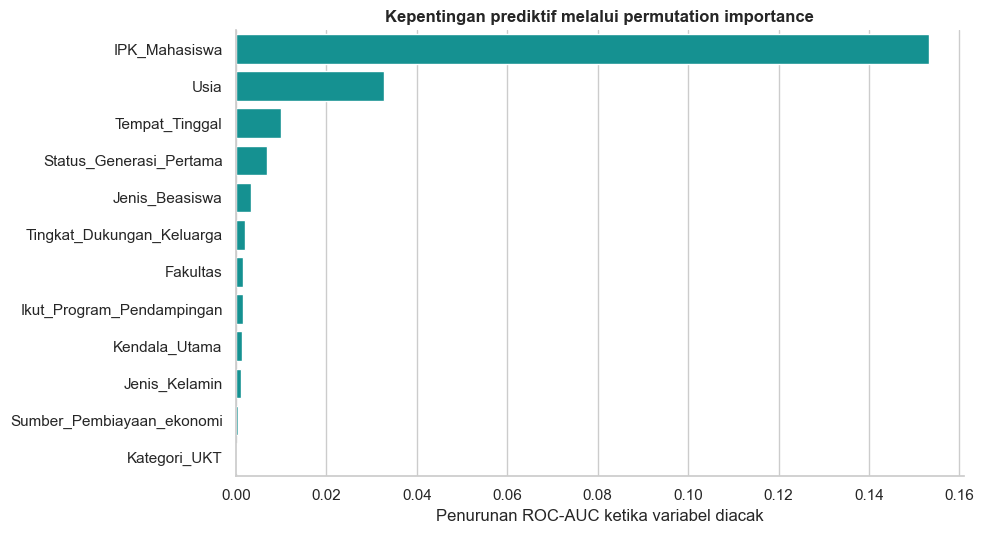

In [27]:
features = ["Kategori_Ekonomi", "Kategori_UKT", "Status_Generasi_Pertama", "Status_Penerima_Beasiswa",
            "Jenis_Beasiswa", "Bekerja_Sambil_Kuliah", "Tingkat_Dukungan_Keluarga", "Jumlah_Tanggungan_Keluarga",
            "Kendala_Utama", "Ikut_Program_Pendampingan", "Sumber_Pembiayaan_ekonomi", "Tempat_Tinggal",
            "Jenis_Kelamin", "Fakultas", "Usia", "IPK_Mahasiswa"]
X, y = df[features], df.punya_catatan_prestasi.astype(int)
categorical = X.select_dtypes(include=["object", "category"]).columns.tolist()
numeric = [c for c in X.columns if c not in categorical]
prep = ColumnTransformer([
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical),
    ("num", Pipeline([("impute", SimpleImputer(strategy="median"))]), numeric),
])
rf = Pipeline([("prep", prep), ("model", RandomForestClassifier(n_estimators=350, min_samples_leaf=8, class_weight="balanced", random_state=42, n_jobs=-1))])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.25, stratify=y, random_state=42)
rf.fit(X_train, y_train)
pred = rf.predict_proba(X_test)[:,1]
print(f"ROC-AUC data uji: {roc_auc_score(y_test, pred):.3f}")

perm = permutation_importance(rf, X_test, y_test, scoring="roc_auc", n_repeats=8, random_state=42, n_jobs=-1)
importance = pd.DataFrame({"variabel":features, "penurunan_AUC":perm.importances_mean, "sd":perm.importances_std}).sort_values("penurunan_AUC", ascending=False)
display(importance.head(15))
sns.barplot(data=importance.head(12), y="variabel", x="penurunan_AUC", color=COLORS["cyan"])
plt.title("Kepentingan prediktif melalui permutation importance"); plt.xlabel("Penurunan ROC-AUC ketika variabel diacak"); plt.ylabel("")
plt.tight_layout(); plt.show()

## 12. Mesin pencari segmen menarik

Segmen dibentuk dari kombinasi ekonomi, generasi pertama, bekerja, beasiswa, dukungan keluarga, dan UKT. Hanya segmen dengan minimal 60 mahasiswa yang dipertahankan. Skor digunakan untuk **menemukan kandidat**, bukan sebagai bukti pentingnya suatu kelompok.

In [28]:
segment_cols = ["Kategori_Ekonomi", "Status_Generasi_Pertama", "Bekerja_Sambil_Kuliah", "Status_Penerima_Beasiswa", "dukungan_keluarga_band", "Kategori_UKT"]
overall = {
    "IPK": df.IPK_Mahasiswa.mean(), "prestasi": df.punya_catatan_prestasi.mean(),
    "nasional_plus": df.prestasi_nasional_plus.mean(), "bekerja": df.bekerja.mean(),
    "cuti_nonaktif": df.cuti_atau_nonaktif.mean(), "kenaikan": df.kenaikan_ipk_1_4.mean(),
}

segments = []
for size in [1, 2, 3]:
    for cols in combinations(segment_cols, size):
        grouped = df.groupby(list(cols), observed=True).agg(
            n=("ID_Mahasiswa","size"), IPK=("IPK_Mahasiswa","mean"),
            prestasi=("punya_catatan_prestasi","mean"), nasional_plus=("prestasi_nasional_plus","mean"),
            bekerja=("bekerja","mean"), cuti_nonaktif=("cuti_atau_nonaktif","mean"),
            kenaikan=("kenaikan_ipk_1_4","mean"), n_kenaikan=("kenaikan_ipk_1_4","count")
        ).reset_index()
        grouped = grouped[grouped.n >= 60]
        for _, row in grouped.iterrows():
            label = " | ".join(f"{c}={row[c]}" for c in cols)
            segments.append({"segmen":label, **{k:row[k] for k in ["n","IPK","prestasi","nasional_plus","bekerja","cuti_nonaktif","kenaikan","n_kenaikan"]}})

segments = pd.DataFrame(segments).drop_duplicates("segmen")
segments["gap_IPK"] = segments.IPK - overall["IPK"]
segments["gap_prestasi_pp"] = (segments.prestasi - overall["prestasi"])*100
segments["gap_nasional_pp"] = (segments.nasional_plus - overall["nasional_plus"])*100
segments["gap_bekerja_pp"] = (segments.bekerja - overall["bekerja"])*100
segments["gap_cuti_pp"] = (segments.cuti_nonaktif - overall["cuti_nonaktif"])*100
segments["gap_kenaikan"] = segments.kenaikan - overall["kenaikan"]

scale_cols = ["gap_IPK","gap_prestasi_pp","gap_nasional_pp","gap_bekerja_pp","gap_cuti_pp","gap_kenaikan"]
z = segments[scale_cols].apply(lambda s:(s-s.mean())/s.std(ddof=0))
segments["skor_keanehan"] = z.abs().mean(axis=1) * np.log1p(segments.n)
display(segments.sort_values("skor_keanehan", ascending=False).head(30).style.format({
    "IPK":"{:.2f}","prestasi":"{:.1%}","nasional_plus":"{:.1%}","bekerja":"{:.1%}","cuti_nonaktif":"{:.1%}",
    "kenaikan":"{:+.2f}","gap_IPK":"{:+.2f}","gap_prestasi_pp":"{:+.1f}","gap_nasional_pp":"{:+.1f}",
    "gap_bekerja_pp":"{:+.1f}","gap_cuti_pp":"{:+.1f}","gap_kenaikan":"{:+.2f}","skor_keanehan":"{:.2f}"}))

,segmen,n,IPK,prestasi,nasional_plus,bekerja,cuti_nonaktif,kenaikan,n_kenaikan,gap_IPK,gap_prestasi_pp,gap_nasional_pp,gap_bekerja_pp,gap_cuti_pp,gap_kenaikan,skor_keanehan
345,Status_Generasi_Pertama=Ya | Bekerja_Sambil_Kuliah=Ya | dukungan_keluarga_band=Rendah (1-2),297.000000,2.75,26.3%,6.4%,100.0%,25.6%,+0.37,190.000000,-0.45,-31.4,-16.8,+75.4,+15.7,+0.12,11.29
160,Kategori_Ekonomi=Rendah | Status_Generasi_Pertama=Ya | Bekerja_Sambil_Kuliah=Ya,377.000000,2.81,28.6%,6.9%,100.0%,25.5%,+0.37,255.000000,-0.40,-29.1,-16.3,+75.4,+15.6,+0.12,11.23
66,Status_Generasi_Pertama=Ya | Bekerja_Sambil_Kuliah=Ya,700.000000,2.84,31.7%,7.7%,100.0%,21.6%,+0.36,467.000000,-0.36,-26.0,-15.4,+75.4,+11.7,+0.11,10.87
335,Status_Generasi_Pertama=Ya | Bekerja_Sambil_Kuliah=Ya | Status_Penerima_Beasiswa=Ya,310.000000,2.87,30.6%,8.7%,100.0%,24.8%,+0.38,216.000000,-0.33,-27.1,-14.5,+75.4,+15.0,+0.13,10.18
173,Kategori_Ekonomi=Tinggi | Status_Generasi_Pertama=Tidak | Status_Penerima_Beasiswa=Ya,195.000000,3.62,85.6%,56.4%,4.1%,5.6%,+0.17,154.000000,+0.42,+27.9,+33.3,-20.5,-4.2,-0.08,9.94
232,Kategori_Ekonomi=Rendah | Bekerja_Sambil_Kuliah=Ya | dukungan_keluarga_band=Rendah (1-2),226.000000,2.82,25.7%,6.2%,100.0%,23.9%,+0.34,148.000000,-0.38,-32.0,-17.0,+75.4,+14.0,+0.10,9.81
97,Bekerja_Sambil_Kuliah=Ya | dukungan_keluarga_band=Rendah (1-2),388.000000,2.83,30.2%,8.8%,100.0%,22.9%,+0.33,252.000000,-0.38,-27.5,-14.4,+75.4,+13.1,+0.08,9.80
29,Kategori_Ekonomi=Rendah | Bekerja_Sambil_Kuliah=Ya,476.000000,2.88,32.8%,8.8%,100.0%,23.1%,+0.33,328.000000,-0.32,-24.9,-14.3,+75.4,+13.2,+0.08,9.70
277,Kategori_Ekonomi=Tinggi | Status_Penerima_Beasiswa=Ya | dukungan_keluarga_band=Tinggi (4-5),163.000000,3.61,85.3%,57.7%,5.5%,6.1%,+0.17,128.000000,+0.41,+27.6,+34.5,-19.0,-3.7,-0.08,9.56
221,Kategori_Ekonomi=Tinggi | Bekerja_Sambil_Kuliah=Tidak | Status_Penerima_Beasiswa=Ya,208.000000,3.58,83.2%,54.3%,0.0%,5.3%,+0.19,167.000000,+0.38,+25.5,+31.2,-24.6,-4.6,-0.06,9.44


## 13. Pemeringkatan faktor menurut besarnya kesenjangan

Tabel ini membandingkan rentang maksimum-minimum antarlevel pada setiap faktor. Faktor dengan banyak level harus ditafsirkan hati-hati; tabel berfungsi sebagai peta eksplorasi.

In [29]:
candidate_factors = ["Kategori_Ekonomi", "Kategori_UKT", "Status_Generasi_Pertama", "Status_Penerima_Beasiswa",
                     "Jenis_Beasiswa", "Bekerja_Sambil_Kuliah", "Tingkat_Dukungan_Keluarga", "Kendala_Utama",
                     "Ikut_Program_Pendampingan", "Sumber_Pembiayaan_ekonomi", "Tempat_Tinggal", "Kepemilikan_Rumah"]
gap_rows = []
for factor in candidate_factors:
    g = outcome_summary(factor)
    for metric in ["IPK", "punya_prestasi", "nasional_plus", "bekerja", "cuti_nonaktif"]:
        hi, lo = g.loc[g[metric].idxmax()], g.loc[g[metric].idxmin()]
        gap_rows.append({"faktor":factor, "metrik":metric, "level_tertinggi":hi[factor], "nilai_tertinggi":hi[metric],
                         "level_terendah":lo[factor], "nilai_terendah":lo[metric], "rentang":hi[metric]-lo[metric],
                         "n_terkecil":g.n.min()})
gaps = pd.DataFrame(gap_rows)
display(gaps.sort_values(["metrik","rentang"], ascending=[True,False]).style.format({"nilai_tertinggi":"{:.3f}","nilai_terendah":"{:.3f}","rentang":"{:.3f}"}))

,faktor,metrik,level_tertinggi,nilai_tertinggi,level_terendah,nilai_terendah,rentang,n_terkecil
20,Jenis_Beasiswa,IPK,Beasiswa Prestasi Akademik (PPA),3.595,KIP-Kuliah,3.062,0.533,126
30,Tingkat_Dukungan_Keluarga,IPK,5.000000,3.383,1.000000,2.932,0.452,294
5,Kategori_UKT,IPK,8.000000,3.386,1.000000,2.941,0.445,207
0,Kategori_Ekonomi,IPK,Tinggi,3.366,Rendah,3.015,0.351,1111
10,Status_Generasi_Pertama,IPK,Tidak,3.335,Ya,2.987,0.348,1924
25,Bekerja_Sambil_Kuliah,IPK,Tidak,3.269,Ya,2.991,0.278,1228
35,Kendala_Utama,IPK,Sosial,3.334,Finansial,3.084,0.250,725
45,Sumber_Pembiayaan_ekonomi,IPK,Orang Tua,3.235,Kerja Sendiri (part-time),3.009,0.226,142
55,Kepemilikan_Rumah,IPK,Milik Sendiri,3.287,Menumpang,3.104,0.184,1041
50,Tempat_Tinggal,IPK,Kos,3.234,Menumpang Saudara,3.099,0.135,294


## 14. Ringkasan kandidat insight untuk infografis

Bagian ini menghasilkan angka headline langsung dari data. Pilih satu cerita utama dan maksimal tiga bukti pendukung agar infografis tidak menjadi dashboard yang terlalu padat.

In [30]:
fg = outcome_summary("Status_Generasi_Pertama").set_index("Status_Generasi_Pertama")
work = outcome_summary("Bekerja_Sambil_Kuliah").set_index("Bekerja_Sambil_Kuliah")
econ = outcome_summary("Kategori_Ekonomi").set_index("Kategori_Ekonomi")
support = outcome_summary("Tingkat_Dukungan_Keluarga").set_index("Tingkat_Dukungan_Keluarga")
coh = cohort_summary

insights = pd.DataFrame([
    {
        "tema":"Mulai lebih jauh, menanjak lebih cepat",
        "headline":f"IPK generasi pertama naik {coh.loc['Ya','kenaikan']:.2f}, dibanding {coh.loc['Tidak','kenaikan']:.2f} pada kelompok lain.",
        "bukti_pendukung":f"Bekerja {fg.loc['Ya','bekerja']:.1%} vs {fg.loc['Tidak','bekerja']:.1%}; catatan prestasi {fg.loc['Ya','punya_prestasi']:.1%} vs {fg.loc['Tidak','punya_prestasi']:.1%}.",
        "catatan":"Gunakan kohort mahasiswa yang sama pada semester 1 dan 4; jangan klaim kausalitas."
    },
    {
        "tema":"Kuliah dalam dua shift",
        "headline":f"Mahasiswa yang bekerja memiliki IPK {work.loc['Ya','IPK']:.2f} dan partisipasi prestasi {work.loc['Ya','punya_prestasi']:.1%}.",
        "bukti_pendukung":f"Kelompok yang tidak bekerja: IPK {work.loc['Tidak','IPK']:.2f}; prestasi {work.loc['Tidak','punya_prestasi']:.1%}.",
        "catatan":"Status bekerja mungkin berkaitan dengan ekonomi dan generasi pertama."
    },
    {
        "tema":"Prestasi memiliki kesenjangan kesempatan",
        "headline":f"Catatan prestasi: ekonomi rendah {econ.loc['Rendah','punya_prestasi']:.1%}, ekonomi tinggi {econ.loc['Tinggi','punya_prestasi']:.1%}.",
        "bukti_pendukung":f"Prestasi nasional/internasional {econ.loc['Rendah','nasional_plus']:.1%} vs {econ.loc['Tinggi','nasional_plus']:.1%}.",
        "catatan":"Dataset tidak mengukur bakat; gunakan istilah kesempatan/partisipasi, bukan kemampuan."
    },
    {
        "tema":"Dukungan keluarga sebagai infrastruktur tak terlihat",
        "headline":f"IPK naik dari {support.loc[1,'IPK']:.2f} pada dukungan 1 menjadi {support.loc[5,'IPK']:.2f} pada dukungan 5.",
        "bukti_pendukung":f"Catatan prestasi berubah dari {support.loc[1,'punya_prestasi']:.1%} menjadi {support.loc[5,'punya_prestasi']:.1%}.",
        "catatan":"Skala 1-5 tidak memiliki label verbal rinci; jelaskan apa adanya."
    },
])
display(insights.style.set_properties(subset=["headline","bukti_pendukung","catatan"], **{"white-space":"pre-wrap"}))

,tema,headline,bukti_pendukung,catatan
0,"Mulai lebih jauh, menanjak lebih cepat","IPK generasi pertama naik 0.35, dibanding 0.19 pada kelompok lain.",Bekerja 36.4% vs 17.2%; catatan prestasi 42.0% vs 67.5%.,Gunakan kohort mahasiswa yang sama pada semester 1 dan 4; jangan klaim kausalitas.
1,Kuliah dalam dua shift,Mahasiswa yang bekerja memiliki IPK 2.99 dan partisipasi prestasi 42.1%.,Kelompok yang tidak bekerja: IPK 3.27; prestasi 62.8%.,Status bekerja mungkin berkaitan dengan ekonomi dan generasi pertama.
2,Prestasi memiliki kesenjangan kesempatan,"Catatan prestasi: ekonomi rendah 41.7%, ekonomi tinggi 73.0%.",Prestasi nasional/internasional 13.4% vs 34.3%.,"Dataset tidak mengukur bakat; gunakan istilah kesempatan/partisipasi, bukan kemampuan."
3,Dukungan keluarga sebagai infrastruktur tak terlihat,IPK naik dari 2.93 pada dukungan 1 menjadi 3.38 pada dukungan 5.,Catatan prestasi berubah dari 33.0% menjadi 72.4%.,Skala 1-5 tidak memiliki label verbal rinci; jelaskan apa adanya.


## 15. Checklist sebelum mengubah temuan menjadi infografis

1. Pilih satu konflik utama: **daya kejar vs beban**, **waktu kerja vs kesempatan**, atau **dukungan vs capaian**.
2. Gunakan persentase mahasiswa, bukan jumlah baris prestasi.
3. Selalu tampilkan ukuran sampel untuk segmen kecil.
4. Untuk tren, batasi semester 1–4 atau gunakan kohort tetap.
5. Gunakan “berkaitan dengan”, “tercatat”, atau “lebih sering”; hindari “menyebabkan”.
6. Jangan menyebut mahasiswa tanpa entri prestasi sebagai “tidak berprestasi”.
7. Pisahkan jenis beasiswa karena target penerimanya berbeda.
8. Pilih maksimal 3–4 angka headline; sisanya menjadi detail pendukung.

Notebook selesai. Tabel `segments`, `gaps`, dan `insights` adalah titik awal terbaik untuk memilih cerita final.